In [6]:
import os
import torch
import numpy as np
from dotenv import load_dotenv
from huggingface_hub import hf_hub_download
import random
from collections import defaultdict
from pathlib import Path

import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
load_dotenv()



True

In [ ]:
# ================= CONFIGURATION =================
# Вкажи свій REPO_ID та назву файлу, який ти завантажила
REPO_ID = os.getenv("REPO_ID")  # Наприклад: "hannusiaknysh/drone-embeddings"
FILENAME = "embeddings/train_positives_embeddings.pt"
# =================================================

print("1. Downloading embeddings from Hugging Face...")
try:
    # Скачуємо файл локально через офіційне API
    file_path = hf_hub_download(repo_id=REPO_ID, filename=FILENAME, repo_type="dataset")
    print(f"File successfully downloaded to: {file_path}")
except Exception as e:
    print(f"Error downloading file: {e}")

print("\n2. Loading embeddings file into memory...")
try:
    embeddings = torch.load(file_path, map_location="cpu", weights_only=False)
    print("Load successful!")
except Exception as e:
    print(f"Error loading PyTorch file: {e}")
    embeddings = None

if embeddings:
    total_frames = len(embeddings)
    print(f"\n3. Analysis:")
    print(f"  - Total frames parsed: {total_frames}")
    
    first_key = list(embeddings.keys())[0]
    first_vector = embeddings[first_key]
    
    print(f"  - Key format example: '{first_key}'")
    print(f"  - Vector type: {type(first_vector)}")
    print(f"  - Vector shape: {first_vector.shape}")

    
    l2_norm = np.linalg.norm(first_vector)
    print(f"  - L2 Norm of vector: {l2_norm:.6f} (Should be ~1.0 if normalized)")
    
    has_nan = np.isnan(first_vector).any()
    has_inf = np.isinf(first_vector).any()
    print(f"  - Contains NaN: {has_nan}")
    print(f"  - Contains Inf: {has_inf}")
    
    expected_frames = 35228
    if total_frames == expected_frames:
        print(f"\n[SUCCESS] Total frame count MATCHES the IoU filter remaining count ({expected_frames}).")
    else:
        print(f"\n[WARNING] Mismatch! Expected: {expected_frames}, Got: {total_frames}")


1. Downloading embeddings from Hugging Face...
File successfully downloaded to: C:\Users\anykn\.cache\huggingface\hub\datasets--hannusia123123--drone_dataset\snapshots\9a4279f0b7e69af1ea3f81c2ebfd57d4cf7c8d2e\embeddings\train_positives_embeddings.pt

2. Loading embeddings file into memory...
Load successful!

3. Analysis:
  - Total frames parsed: 35228
  - Key format example: 'cross_rgb_complex_006_f0001.jpg'
  - Vector type: <class 'numpy.ndarray'>
  - Vector shape: (1536,)
  - L2 Norm of vector: 1.000000 (Should be ~1.0 if normalized)
  - Contains NaN: False
  - Contains Inf: False

[SUCCESS] Total frame count MATCHES the IoU filter remaining count (35228).


### **Theta Analysis**

In [ ]:
# ================= CONFIGURATION =================
SAMPLE_VIDEOS = 50  # Number of videos to sample for θ₁ analysis
SAMPLE_PAIRS = 50_000  # Number of random pairs for dataset-level histogram
THETA_STEPS = 50  # Number of steps on the elbow curve
# ======================================


# -------------------------------------------------
# 1. Group frames by video source
# -------------------------------------------------
def group_by_video(embeddings_dict: dict) -> dict[str, list]:
    groups = defaultdict(list)
    for filename, emb in embeddings_dict.items():
        # Trim '_fXXXX.jpg' to get the unique video identifier
        stem = Path(filename).stem  # e.g., 'cross_rgb_complex_006_f0001'
        video_id = "_".join(stem.split("_")[:-1])  # e.g., 'cross_rgb_complex_006'
        groups[video_id].append((filename, emb))

    print(f"  {len(groups):,} unique videos found")
    print(
        f"  Average number of frames per video: {np.mean([len(v) for v in groups.values()]):.1f}"
    )
    return dict(groups)


# -------------------------------------------------
# 2. Pairwise Cosine Distance calculation
# -------------------------------------------------
def pairwise_distances(embeddings_array: np.ndarray) -> np.ndarray:
    """embeddings_array: (N, D) → returns (N*(N-1)/2) pairwise distances"""
    sim = embeddings_array @ embeddings_array.T  # (N, N) dot product
    sim = np.clip(sim, -1.0, 1.0)
    dist = 1.0 - sim  # Cosine distance
    idx = np.triu_indices(len(embeddings_array), k=1)
    return dist[idx]


# -------------------------------------------------
# 3. Analyze θ₁ (Intra-video distance)
# -------------------------------------------------
def analyze_theta1(groups: dict, sample_n: int = 50) -> np.ndarray:
    print(f"\n{'='*50}")
    print(f"ANALYSIS θ₁ (video level) — sample of {sample_n} videos")
    print(f"{'='*50}")

    video_ids = random.sample(list(groups.keys()), min(sample_n, len(groups)))
    all_distances = []

    for vid in tqdm(video_ids, desc="Pairwise distances within videos"):
        frames = groups[vid]
        if len(frames) < 2:
            continue
        embs = np.stack([e for _, e in frames])  # (N, 1536)
        dists = pairwise_distances(embs)
        all_distances.append(dists)

    all_distances = np.concatenate(all_distances)
    print(f"  {len(all_distances):,} pairs counted")
    print(
        f"  Min: {all_distances.min():.4f}  Max: {all_distances.max():.4f}  Mean: {all_distances.mean():.4f}"
    )
    return all_distances


# -------------------------------------------------
# 4. Analyze θ₂ (Inter-video distance)
# -------------------------------------------------
def analyze_theta2(embeddings_dict: dict, sample_n: int = 50_000) -> np.ndarray:
    print(f"\n{'='*50}")
    print(f"ANALYSIS θ₂ (dataset level) — {sample_n:,} random pairs")
    print(f"{'='*50}")

    all_embs = np.stack(list(embeddings_dict.values()))  # (N, 1536)
    idx1 = np.random.randint(0, len(all_embs), sample_n)
    idx2 = np.random.randint(0, len(all_embs), sample_n)

    mask = idx1 != idx2
    idx1, idx2 = idx1[mask], idx2[mask]

    dists = 1.0 - np.clip(
        np.sum(all_embs[idx1] * all_embs[idx2], axis=1), -1.0, 1.0
    )
    print(f"  {len(dists):,} pairs counted")
    print(
        f"  Min: {dists.min():.4f}  Max: {dists.max():.4f}  Mean: {dists.mean():.4f}"
    )
    return dists


# -------------------------------------------------
# 5. Simulate the Elbow Curve for θ₁
# -------------------------------------------------
def elbow_curve(
    groups: dict, sample_n: int = 30, theta_steps: int = 50
) -> tuple[np.ndarray, np.ndarray]:
    print(f"\nPlotting the elbow curve for θ₁...")

    video_ids = random.sample(list(groups.keys()), min(sample_n, len(groups)))
    theta_range = np.linspace(0.01, 0.8, theta_steps)
    kept_fractions = []

    for theta in tqdm(theta_range, desc="Elbow curve"):
        total, kept = 0, 0
        for vid in video_ids:
            frames = groups[vid]
            if len(frames) < 2:
                kept += len(frames)
                total += len(frames)
                continue
            embs = np.stack([e for _, e in frames])
            sim = embs @ embs.T
            np.fill_diagonal(sim, -2.0)  # Exclude self-comparison
            nearest = 1.0 - sim.max(axis=1)  # Minimum distance to the closest neighbor
            kept += int((nearest >= theta).sum())
            total += len(frames)

        kept_fractions.append(kept / total if total > 0 else 0)

    return theta_range, np.array(kept_fractions)


# -------------------------------------------------
# 6. Plot graphs directly in the Notebook output
# -------------------------------------------------
def plot_analysis_inline(
    dist_intra: np.ndarray,
    dist_inter: np.ndarray,
    theta_range: np.ndarray,
    kept_fractions: np.ndarray,
):
    fig = plt.figure(figsize=(16, 11))
    fig.suptitle(
        "Analysis of θ Thresholds for k-Center Greedy",
        fontsize=14,
        fontweight="bold",
    )
    gs = gridspec.GridSpec(2, 2, figure=fig, hspace=0.35, wspace=0.25)

    # --- Plot 1: Histogram of intra-video distances ---
    ax1 = fig.add_subplot(gs[0, 0])
    ax1.hist(
        dist_intra, bins=100, color="#4A90D9", alpha=0.8, edgecolor="none"
    )
    ax1.set_title("Distances Within the Same Video (θ₁)", fontsize=11, weight="bold")
    ax1.set_xlabel("Cosine distance")
    ax1.set_ylabel("Number of pairs")

    p10 = np.percentile(dist_intra, 10)
    p25 = np.percentile(dist_intra, 25)
    med = np.median(dist_intra)
    ax1.axvline(
        p10, color="red", linestyle="--", linewidth=1.2, label=f"p10={p10:.3f}"
    )
    ax1.axvline(
        p25,
        color="orange",
        linestyle="--",
        linewidth=1.2,
        label=f"p25={p25:.3f}",
    )
    ax1.axvline(
        med,
        color="green",
        linestyle="--",
        linewidth=1.2,
        label=f"median={med:.3f}",
    )
    ax1.legend(fontsize=9)
    ax1.grid(True, alpha=0.2)

    # --- Plot 2: Histogram of inter-video distances ---
    ax2 = fig.add_subplot(gs[0, 1])
    ax2.hist(
        dist_inter, bins=100, color="#E67E22", alpha=0.8, edgecolor="none"
    )
    ax2.set_title(
        "Distances Between Different Videos (θ₂)", fontsize=11, weight="bold"
    )
    ax2.set_xlabel("Cosine distance")
    ax2.set_ylabel("Number of pairs")

    p25_inter = np.percentile(dist_inter, 25)
    med_inter = np.median(dist_inter)
    p75_inter = np.percentile(dist_inter, 75)
    ax2.axvline(
        p25_inter,
        color="orange",
        linestyle="--",
        linewidth=1.2,
        label=f"p25={p25_inter:.3f}",
    )
    ax2.axvline(
        med_inter,
        color="green",
        linestyle="--",
        linewidth=1.2,
        label=f"median={med_inter:.3f}",
    )
    ax2.axvline(
        p75_inter,
        color="purple",
        linestyle="--",
        linewidth=1.2,
        label=f"p75={p75_inter:.3f}",
    )
    ax2.legend(fontsize=9)
    ax2.grid(True, alpha=0.2)

    # --- Plot 3: Elbow Curve ---
    ax3 = fig.add_subplot(gs[1, 0])
    ax3.plot(theta_range, kept_fractions * 100, color="#2ECC71", linewidth=2)
    ax3.set_title(
        "Elbow Curve: θ₁ vs % of Frames Retained", fontsize=11, weight="bold"
    )
    ax3.set_xlabel("θ₁")
    ax3.set_ylabel("% of frames retained")
    ax3.grid(True, alpha=0.3)

    # Find the elbow point using the second derivative
    second_deriv = np.gradient(np.gradient(kept_fractions))
    elbow_idx = np.argmax(np.abs(second_deriv))
    elbow_theta = theta_range[elbow_idx]
    ax3.axvline(
        elbow_theta,
        color="red",
        linestyle="--",
        linewidth=1.5,
        label=f"elbow ≈ {elbow_theta:.3f}",
    )
    ax3.legend(fontsize=9)

    # --- Plot 4: Combined distributions comparison ---
    ax4 = fig.add_subplot(gs[1, 1])
    ax4.hist(
        dist_intra,
        bins=80,
        color="#4A90D9",
        alpha=0.6,
        density=True,
        label="within the video (θ₁)",
    )
    ax4.hist(
        dist_inter,
        bins=80,
        color="#E67E22",
        alpha=0.6,
        density=True,
        label="between videos (θ₂)",
    )
    ax4.set_title("Comparison of Distributions", fontsize=11, weight="bold")
    ax4.set_xlabel("Cosine distance")
    ax4.set_ylabel("Density")
    ax4.legend(fontsize=9)
    ax4.grid(True, alpha=0.2)

    # Render plots inline
    plt.show()

    return elbow_theta


# -------------------------------------------------
# 7. Print Recommendations report
# -------------------------------------------------
def print_recommendations(dist_intra, dist_inter, elbow_theta):
    print(f"\n{'='*50}")
    print("RECOMMENDATIONS FOR θ")
    print(f"{'='*50}")

    theta1_conservative = np.percentile(dist_intra, 10)
    theta1_elbow = elbow_theta
    theta1_moderate = np.percentile(dist_intra, 25)

    print(f"\nθ₁ (video-level threshold):")
    print(
        f"  Conservative (p10):   {theta1_conservative:.4f}  — removes ~10% of the most static pairs"
    )
    print(
        f"  Elbow curve:          {theta1_elbow:.4f}  — optimal balance of dataset size & diversity"
    )
    print(
        f"  Moderate     (p25):   {theta1_moderate:.4f}  — more aggressive frame removal"
    )

    theta2_conservative = np.percentile(dist_inter, 15)
    theta2_moderate = np.percentile(dist_inter, 30)

    print(f"\nθ₂ (dataset-level threshold):")
    print(
        f"  Conservative (p15):   {theta2_conservative:.4f}  — removes redundant duplicate scenes"
    )
    print(
        f"  Moderate     (p30):   {theta2_moderate:.4f}  — more aggressive dataset pruning"
    )

    print(f"\nRecommendation: start with θ₁={theta1_elbow:.3f} and θ₂={theta2_conservative:.3f}")
    print(f"                after running Greedy selection, visually verify results on 2-3 videos")
    print(f"                and adjust parameters if needed")


# -------------------------------------------------
# Main execution workflow
# -------------------------------------------------
def run_theta_analysis(embeddings_dict: dict):
    random.seed(42)
    np.random.seed(42)

    if not embeddings_dict:
        print("Error: Embeddings dictionary is empty!")
        return

    # 1. Group frames by video source
    groups = group_by_video(embeddings_dict)

    # 2. Analyze theta1 (intra-video distances)
    dist_intra = analyze_theta1(groups, sample_n=SAMPLE_VIDEOS)

    # 3. Analyze theta2 (inter-video distances)
    dist_inter = analyze_theta2(embeddings_dict, sample_n=SAMPLE_PAIRS)

    # 4. Compute the elbow curve
    theta_range, kept_fractions = elbow_curve(
        groups, sample_n=30, theta_steps=THETA_STEPS
    )

    # 5. Visualize metrics and calculate the elbow threshold
    elbow_theta = plot_analysis_inline(
        dist_intra, dist_inter, theta_range, kept_fractions
    )

    # 6. Print final data recommendations
    print_recommendations(dist_intra, dist_inter, elbow_theta)




  423 unique videos found
  Average number of frames per video: 83.3

ANALYSIS θ₁ (video level) — sample of 50 videos


Pairwise distances within videos: 100%|██████████| 50/50 [00:00<00:00, 2713.11it/s]

  145,880 pairs counted
  Min: 0.0011  Max: 0.9973  Mean: 0.2827

ANALYSIS θ₂ (dataset level) — 50,000 random pairs


  50,000 pairs counted
  Min: 0.0148  Max: 1.0799  Mean: 0.6472

Plotting the elbow curve for θ₁...


Elbow curve: 100%|██████████| 50/50 [00:00<00:00, 82.59it/s]


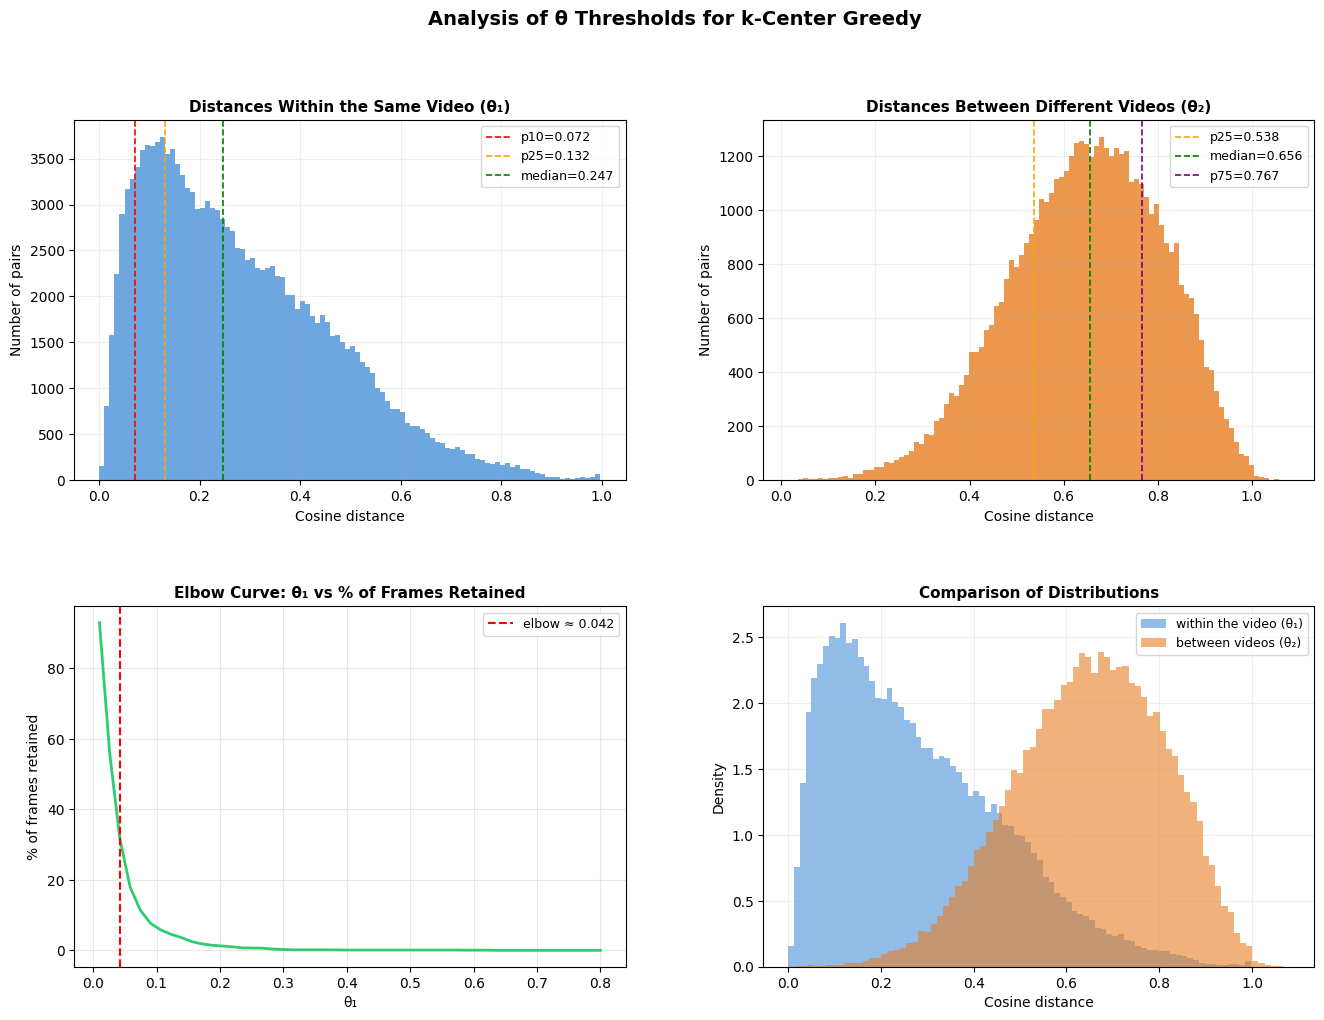


RECOMMENDATIONS FOR θ

θ₁ (video-level threshold):
  Conservative (p10):   0.0721  — removes ~10% of the most static pairs
  Elbow curve:          0.0422  — optimal balance of dataset size & diversity
  Moderate     (p25):   0.1323  — more aggressive frame removal

θ₂ (dataset-level threshold):
  Conservative (p15):   0.4745  — removes redundant duplicate scenes
  Moderate     (p30):   0.5645  — more aggressive dataset pruning

Recommendation: start with θ₁=0.042 and θ₂=0.474
                after running Greedy selection, visually verify results on 2-3 videos
                and adjust parameters if needed


In [ ]:
# ===========# =================================================
# EXECUTE ANALYSIS
# (Passes the 'embeddings' variable loaded in the previous step)
# =================================================
run_theta_analysis(embeddings)

Found 8,228 frames remaining in E:\bachelor_data\extracted_dataset\train\RAW_POSITIVES
Filtered embeddings: 8,228 active vectors (down from 35,228)
Grouped into 423 unique videos
Frames per video — Mean: 19.5, Min: 2, Max: 103

Computing 50,000 inter-video pairwise distances...


Sampling inter-video pairs: 100%|██████████| 50000/50000 [00:01<00:00, 28129.39it/s]


Min: 0.0538  Max: 1.1127  Mean: 0.6969  Median: 0.7052


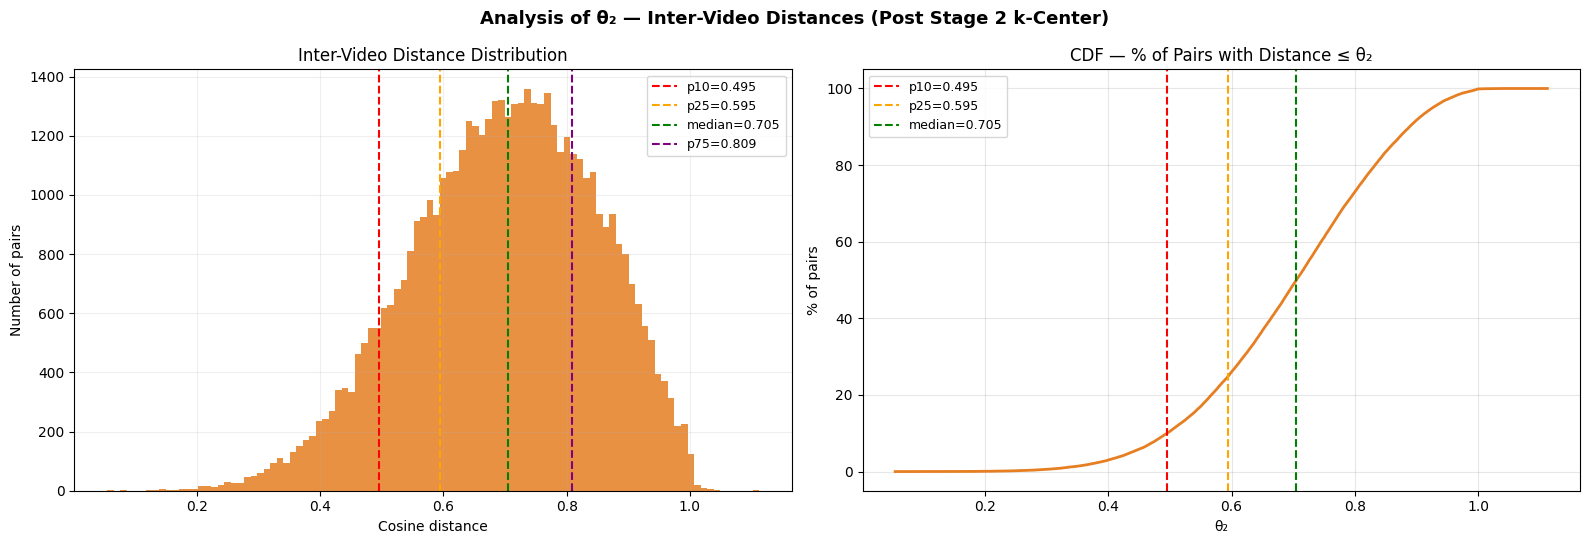


RECOMMENDATIONS FOR θ₂
  p10 = 0.4952  — Highly conservative (removes only identical background setups)
  p25 = 0.5949  — Moderate (excellent target starting point)
  median = 0.7052  — Aggressive (keeps only extremely distinct scenes)

If the left tail of your histogram starts above 0.35 - 0.40:
  -> Your videos are already highly distinct.
  -> Stage 3 global deduplication is likely NOT necessary.


In [2]:
import os
import re
import glob
import torch
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from collections import defaultdict
from tqdm.auto import tqdm

# ================= CONFIGURATION =================
# Resolve the processed data path from .env
EXTRACTED_DATA_PATH = os.getenv("EXTRACTED_DATA_PATH")
FILTERED_DATA_DIR = Path(EXTRACTED_DATA_PATH) / "train" / "RAW_POSITIVES"
SAMPLE_PAIRS = 50_000   # Number of random cross-video pairs to sample
EMBEDDINGS_DIR = Path(os.getenv("EMBEDDINGS_DIR")) 
embedding_type = "positives" 
emb_file_name = f"train_positives_embeddings.pt"
emb_path = EMBEDDINGS_DIR / embedding_type / emb_file_name
embeddings = torch.load(emb_path, map_location="cpu", weights_only=False)

# =================================================


# -------------------------------------------------
# 1. Collect names of surviving frames (Stage 2 survivors)
# -------------------------------------------------
def collect_surviving_frames(data_dir: Path) -> set[str]:
    pattern = str(data_dir / "*.jpg")
    files = glob.glob(pattern)
    names = {Path(f).name for f in files}
    print(f"Found {len(names):,} frames remaining in {data_dir}")
    return names


# -------------------------------------------------
# 2. Filter the active in-memory embeddings dictionary
# -------------------------------------------------
def filter_active_embeddings(embeddings_dict: dict, surviving_names: set[str]) -> dict[str, np.ndarray]:
    filtered = {}
    for k, v in embeddings_dict.items():
        if k in surviving_names:
            # Convert PyTorch tensors to NumPy arrays if necessary
            filtered[k] = v.numpy() if isinstance(v, torch.Tensor) else np.array(v)

    print(f"Filtered embeddings: {len(filtered):,} active vectors (down from {len(embeddings_dict):,})")
    return filtered


# -------------------------------------------------
# 3. Group embeddings by Video ID (robust regex)
# -------------------------------------------------
def group_by_video(embeddings_dict: dict) -> dict[str, list]:
    groups = defaultdict(list)
    for filename, emb in embeddings_dict.items():
        stem = Path(filename).stem
        # Safely remove only the final '_fXXXX' (frame index)
        video_id = re.sub(r'_f\d+$', '', stem)
        groups[video_id].append(emb)

    print(f"Grouped into {len(groups):,} unique videos")
    sizes = [len(v) for v in groups.values()]
    print(f"Frames per video — Mean: {np.mean(sizes):.1f}, "
          f"Min: {np.min(sizes)}, Max: {np.max(sizes)}")
    return dict(groups)


# -------------------------------------------------
# 4. Compute cross-video pairwise distances
# -------------------------------------------------
def compute_inter_video_distances(groups_dict: dict, sample_n: int = 50_000) -> np.ndarray:
    print(f"\nComputing {sample_n:,} inter-video pairwise distances...")

    video_ids = list(groups_dict.keys())
    all_embs_per_video = [np.stack(groups_dict[v]) for v in video_ids]

    dists = []
    rng = np.random.default_rng(42)

    with tqdm(total=sample_n, desc="Sampling inter-video pairs") as pbar:
        while len(dists) < sample_n:
            # Pick two different random videos
            i, j = rng.choice(len(video_ids), size=2, replace=False)
            embs_i = all_embs_per_video[i]
            embs_j = all_embs_per_video[j]

            # Grab one random frame from each video
            ei = embs_i[rng.integers(len(embs_i))]
            ej = embs_j[rng.integers(len(embs_j))]

            # Compute L2-normalized cosine distance (1.0 - dot_product)
            dist = 1.0 - float(np.clip(ei @ ej, -1.0, 1.0))
            dists.append(dist)
            pbar.update(1)

    dists = np.array(dists)
    print(f"Min: {dists.min():.4f}  Max: {dists.max():.4f}  "
          f"Mean: {dists.mean():.4f}  Median: {np.median(dists):.4f}")
    return dists


# -------------------------------------------------
# 5. Render plots inline and print recommendations
# -------------------------------------------------
def plot_and_recommend(dists: np.ndarray):
    p10  = np.percentile(dists, 10)
    p25  = np.percentile(dists, 25)
    med  = np.median(dists)
    p75  = np.percentile(dists, 75)

    fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
    fig.suptitle("Analysis of θ₂ — Inter-Video Distances (Post Stage 2 k-Center)",
                 fontsize=13, fontweight="bold")

    # Subplot 1: Distance Histogram
    ax = axes[0]
    ax.hist(dists, bins=100, color="#E67E22", alpha=0.85, edgecolor="none")
    ax.axvline(p10, color="red",    linestyle="--", lw=1.5, label=f"p10={p10:.3f}")
    ax.axvline(p25, color="orange", linestyle="--", lw=1.5, label=f"p25={p25:.3f}")
    ax.axvline(med, color="green",  linestyle="--", lw=1.5, label=f"median={med:.3f}")
    ax.axvline(p75, color="purple", linestyle="--", lw=1.5, label=f"p75={p75:.3f}")
    ax.set_title("Inter-Video Distance Distribution")
    ax.set_xlabel("Cosine distance")
    ax.set_ylabel("Number of pairs")
    ax.grid(True, alpha=0.2)
    ax.legend(fontsize=9)

    # Subplot 2: Cumulative Distribution Function (CDF)
    ax2 = axes[1]
    sorted_d = np.sort(dists)
    cdf = np.arange(1, len(sorted_d) + 1) / len(sorted_d)
    ax2.plot(sorted_d, cdf * 100, color="#E67E22", lw=2)
    for thresh, color, label in [
        (p10, "red",    f"p10={p10:.3f}"),
        (p25, "orange", f"p25={p25:.3f}"),
        (med, "green",  f"median={med:.3f}"),
    ]:
        ax2.axvline(thresh, color=color, linestyle="--", lw=1.5, label=label)
    ax2.set_title("CDF — % of Pairs with Distance ≤ θ₂")
    ax2.set_xlabel("θ₂")
    ax2.set_ylabel("% of pairs")
    ax2.legend(fontsize=9)
    ax2.grid(True, alpha=0.3)

    # Render plots inline in the Notebook
    plt.tight_layout()
    plt.show()

    # Console Recommendations Report
    print(f"\n{'='*50}")
    print("RECOMMENDATIONS FOR θ₂")
    print(f"{'='*50}")
    print(f"  p10 = {p10:.4f}  — Highly conservative (removes only identical background setups)")
    print(f"  p25 = {p25:.4f}  — Moderate (excellent target starting point)")
    print(f"  median = {med:.4f}  — Aggressive (keeps only extremely distinct scenes)")
    print(f"\nIf the left tail of your histogram starts above 0.35 - 0.40:")
    print("  -> Your videos are already highly distinct.")
    print("  -> Stage 3 global deduplication is likely NOT necessary.")


# -------------------------------------------------
# Notebook Execution Flow
# -------------------------------------------------
def run_post_deduplication_analysis(in_memory_embeddings: dict):
    if not FILTERED_DATA_DIR.exists():
        print(f"Error: Checked path does not exist: {FILTERED_DATA_DIR}")
        print("Please verify 'EXTRACTED_DATA_PATH' in your environment or .env file.")
        return

    # 1. Scan actual files present on the E: disk
    surviving_names = collect_surviving_frames(FILTERED_DATA_DIR)
    
    # 2. Filter the existing in-memory dict
    filtered_embs = filter_active_embeddings(in_memory_embeddings, surviving_names)
    
    # 3. Group by video ID
    groups = group_by_video(filtered_embs)
    
    # 4. Sample distances
    dists = compute_inter_video_distances(groups, sample_n=SAMPLE_PAIRS)
    
    # 5. Plot and print metrics
    plot_and_recommend(dists)


# Run the analysis using your active loaded 'embeddings' dict
run_post_deduplication_analysis(embeddings)

In [ ]:
import os
import torch
import numpy as np
from dotenv import load_dotenv
from huggingface_hub import hf_hub_download

load_dotenv()

# ================= CONFIGURATION =================
# Вкажи свій REPO_ID та назву файлу, який ти завантажила
REPO_ID = os.getenv("REPO_ID")  # Наприклад: "hannusiaknysh/drone-embeddings"
FILENAME = "embeddings/train_negatives_embeddings.pt"
# =================================================

print("1. Downloading embeddings from Hugging Face...")
try:
    # Скачуємо файл локально через офіційне API
    file_path = hf_hub_download(repo_id=REPO_ID, filename=FILENAME, repo_type="dataset")
    print(f"File successfully downloaded to: {file_path}")
except Exception as e:
    print(f"Error downloading file: {e}")

print("\n2. Loading embeddings file into memory...")
try:
    embeddings = torch.load(file_path, map_location="cpu", weights_only=False)
    print("Load successful!")
except Exception as e:
    print(f"Error loading PyTorch file: {e}")
    embeddings = None

d:\anykn\python\bachelor\drone_classification\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


1. Downloading embeddings from Hugging Face...
File successfully downloaded to: C:\Users\anykn\.cache\huggingface\hub\datasets--hannusia123123--drone_dataset\snapshots\e4afa1a90a1a364ef893dd98a51d6ab7ee07f734\embeddings\train_negatives_embeddings.pt

2. Loading embeddings file into memory...
Load successful!


In [2]:
if embeddings:
    total_frames = len(embeddings)
    print(f"\n3. Analysis:")
    print(f"  - Total frames parsed: {total_frames}")
    
    first_key = list(embeddings.keys())[0]
    first_vector = embeddings[first_key]
    
    print(f"  - Key format example: '{first_key}'")
    print(f"  - Vector type: {type(first_vector)}")
    print(f"  - Vector shape: {first_vector.shape}")

    
    l2_norm = np.linalg.norm(first_vector)
    print(f"  - L2 Norm of vector: {l2_norm:.6f} (Should be ~1.0 if normalized)")
    
    has_nan = np.isnan(first_vector).any()
    has_inf = np.isinf(first_vector).any()
    print(f"  - Contains NaN: {has_nan}")
    print(f"  - Contains Inf: {has_inf}")
    
    expected_frames = 35228
    if total_frames == expected_frames:
        print(f"\n[SUCCESS] Total frame count MATCHES the IoU filter remaining count ({expected_frames}).")
    else:
        print(f"\n[WARNING] Mismatch! Expected: {expected_frames}, Got: {total_frames}")


In [12]:
# ================= CONFIGURATION =================
# Вкажи свій REPO_ID та назву файлу, який ти завантажила
REPO_ID = os.getenv("REPO_ID")  # Наприклад: "hannusiaknysh/drone-embeddings"
FILENAME = "embeddings/train_negatives_embeddings.pt"
# =================================================

print("1. Downloading embeddings from Hugging Face...")
try:
    # Скачуємо файл локально через офіційне API
    file_path = hf_hub_download(repo_id=REPO_ID, filename=FILENAME, repo_type="dataset")
    print(f"File successfully downloaded to: {file_path}")
except Exception as e:
    print(f"Error downloading file: {e}")

print("\n2. Loading embeddings file into memory...")
try:
    embeddings = torch.load(file_path, map_location="cpu", weights_only=False)
    print("Load successful!")
except Exception as e:
    print(f"Error loading PyTorch file: {e}")
    embeddings = None

if embeddings:
    total_frames = len(embeddings)
    print(f"\n3. Analysis:")
    print(f"  - Total frames parsed: {total_frames}")
    
    first_key = list(embeddings.keys())[0]
    first_vector = embeddings[first_key]
    
    print(f"  - Key format example: '{first_key}'")
    print(f"  - Vector type: {type(first_vector)}")
    print(f"  - Vector shape: {first_vector.shape}")

    
    l2_norm = np.linalg.norm(first_vector)
    print(f"  - L2 Norm of vector: {l2_norm:.6f} (Should be ~1.0 if normalized)")
    
    has_nan = np.isnan(first_vector).any()
    has_inf = np.isinf(first_vector).any()
    print(f"  - Contains NaN: {has_nan}")
    print(f"  - Contains Inf: {has_inf}")
    
    expected_frames = 35228
    if total_frames == expected_frames:
        print(f"\n[SUCCESS] Total frame count MATCHES the IoU filter remaining count ({expected_frames}).")
    else:
        print(f"\n[WARNING] Mismatch! Expected: {expected_frames}, Got: {total_frames}")


1. Downloading embeddings from Hugging Face...
File successfully downloaded to: C:\Users\anykn\.cache\huggingface\hub\datasets--hannusia123123--drone_dataset\snapshots\e4afa1a90a1a364ef893dd98a51d6ab7ee07f734\embeddings\train_negatives_embeddings.pt

2. Loading embeddings file into memory...
Load successful!


In [13]:
# NEGATIVES_EMB_PATH = Path(os.getenv("EMBEDDINGS_DIR")) / "negatives" / "train_negatives_embeddings.pt"
# neg_embeddings = torch.load(NEGATIVES_EMB_PATH, map_location="cpu", weights_only=False)
run_theta_analysis(embeddings)

Error: Embeddings dictionary is empty!


1. Downloading NEGATIVES embeddings from Hugging Face...


d:\anykn\python\bachelor\drone_classification\.venv\Lib\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\anykn\.cache\huggingface\hub\datasets--hannusia123123--drone_dataset. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


File successfully downloaded to: C:\Users\anykn\.cache\huggingface\hub\datasets--hannusia123123--drone_dataset\snapshots\a4ca4d8efb03ccafc514471fc519d46cf7b82c57\embeddings\train_negatives_embeddings.pt

2. Loading negatives embeddings into memory...
Load successful! Found 5,938 active keys.

3. Starting analysis on Negatives...
  69 unique videos found
  Average number of frames per video: 86.1

ANALYSIS θ₁ (video level) — sample of 50 videos


Pairwise distances within videos: 100%|██████████| 50/50 [00:00<00:00, 223.82it/s]


  3,185,199 pairs counted
  Min: 0.0000  Max: 0.7274  Mean: 0.0234

ANALYSIS θ₂ (dataset level) — 50,000 random pairs
  49,993 pairs counted
  Min: 0.0000  Max: 0.9835  Mean: 0.4610

Plotting the elbow curve for θ₁...


Elbow curve: 100%|██████████| 50/50 [00:00<00:00, 93.56it/s]


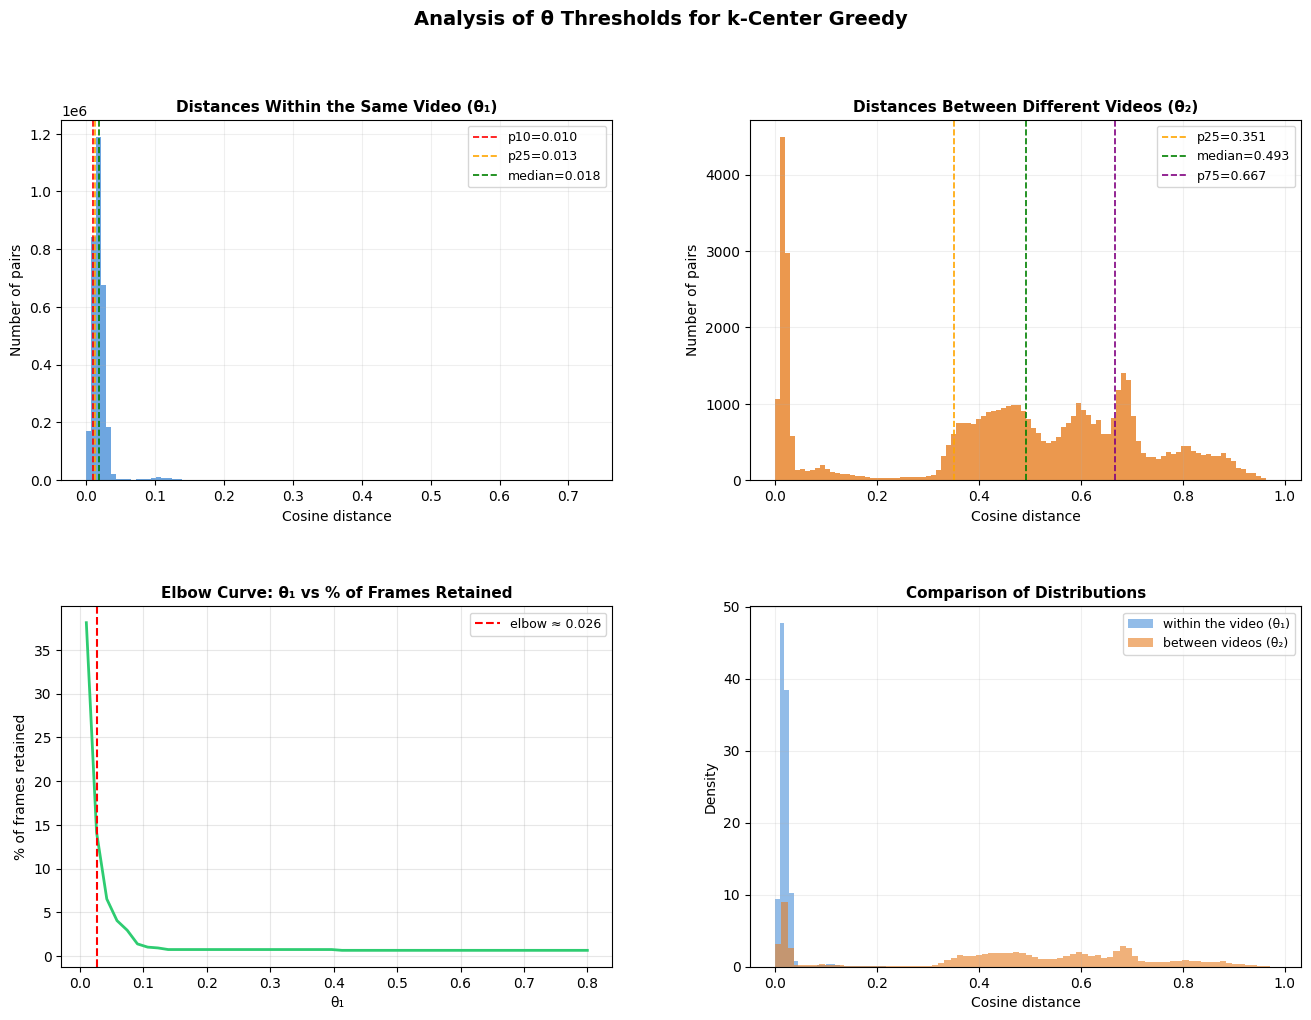


RECOMMENDATIONS FOR θ

θ₁ (video-level threshold):
  Conservative (p10):   0.0097  — removes ~10% of the most static pairs
  Elbow curve:          0.0261  — optimal balance of dataset size & diversity
  Moderate     (p25):   0.0133  — more aggressive frame removal

θ₂ (dataset-level threshold):
  Conservative (p15):   0.0248  — removes redundant duplicate scenes
  Moderate     (p30):   0.3837  — more aggressive dataset pruning

Recommendation: start with θ₁=0.026 and θ₂=0.025
                after running Greedy selection, visually verify results on 2-3 videos
                and adjust parameters if needed


In [15]:
import os
import torch
from huggingface_hub import hf_hub_download

# ================= CONFIGURATION =================
# REPO_ID will be loaded from your local .env file
REPO_ID = os.getenv("REPO_ID")  
# We specify the negatives file path in your Hugging Face repo
FILENAME = "embeddings/train_negatives_embeddings.pt"
# =================================================

print("1. Downloading NEGATIVES embeddings from Hugging Face...")
try:
    # Securely download the negatives file directly via HF API
    file_path = hf_hub_download(repo_id=REPO_ID, filename=FILENAME, repo_type="dataset")
    print(f"File successfully downloaded to: {file_path}")
except Exception as e:
    print(f"Error downloading file from Hugging Face: {e}")
    file_path = None

if file_path:
    print("\n2. Loading negatives embeddings into memory...")
    try:
        neg_embeddings = torch.load(file_path, map_location="cpu", weights_only=False)
        print(f"Load successful! Found {len(neg_embeddings):,} active keys.")
    except Exception as e:
        print(f"Error loading PyTorch file: {e}")
        neg_embeddings = None

    if neg_embeddings and len(neg_embeddings) > 0:
        print("\n3. Starting analysis on Negatives...")
        # Run your working analysis workflow
        run_theta_analysis(neg_embeddings)
    else:
        print("\n[WARNING] The loaded dictionary is empty! This means:")
        print("  1. The Kaggle notebook saved 0 embeddings (e.g. RAW_NEGATIVES folder was empty).")
        print("  2. Or you need to run/re-run the Kaggle generator script for negatives.")

In [1]:
"""
Діагностика: перевірка наявності відео в словнику ембедингів
=============================================================
Перевіряє чи існують кадри з конкретних відео в файлі ембедингів.
"""

import torch
import re
from pathlib import Path
from collections import defaultdict

# ================= КОНФІГУРАЦІЯ =================
EMBEDDINGS_PATH = r"E:\bachelor_data\embeddings\negatives\train_negatives_embeddings.pt"

# Відео які підозрюємо що відсутні
SUSPECT_VIDEOS = [
    "no_drone_rgb_sky_596",
    "no_drone_thermal_complex_601",
    "no_drone_rgb_field_599",
    "no_drone_rgb_complex_597",
]
# =================================================


def main():
    print(f"Завантаження ембедингів з {EMBEDDINGS_PATH}...")
    embeddings = torch.load(EMBEDDINGS_PATH, map_location="cpu", weights_only=False)
    print(f"Всього ключів у словнику: {len(embeddings):,}")
    print()

    # Групуємо всі ключі по відео
    video_groups = defaultdict(list)
    for filename in embeddings.keys():
        stem = Path(filename).stem
        video_id = re.sub(r'_f\d+$', '', stem)
        video_groups[video_id].append(filename)

    print(f"Унікальних відео в словнику: {len(video_groups):,}")
    print()

    # Перевіряємо підозрілі відео
    print("=" * 60)
    print("ПЕРЕВІРКА ПІДОЗРІЛИХ ВІДЕО")
    print("=" * 60)

    for video_id in SUSPECT_VIDEOS:
        if video_id in video_groups:
            frames = video_groups[video_id]
            print(f"✓ ЗНАЙДЕНО: {video_id}")
            print(f"  Кількість кадрів: {len(frames)}")
            print(f"  Приклад ключа: {frames[0]}")
        else:
            print(f"✗ ВІДСУТНЄ: {video_id}")
            # Шукаємо схожі назви (можливо інший формат)
            similar = [v for v in video_groups.keys()
                      if any(part in v for part in video_id.split('_')[-3:])]
            if similar:
                print(f"  Схожі назви в словнику: {similar[:5]}")
        print()

    # Показуємо всі відео які є в словнику
    print("=" * 60)
    print("ВСІ ВІДЕО В СЛОВНИКУ ЕМБЕДИНГІВ")
    print("=" * 60)
    for video_id, frames in sorted(video_groups.items()):
        print(f"  {video_id}: {len(frames)} кадрів")

    # Перевіряємо формат ключів
    print()
    print("=" * 60)
    print("ФОРМАТ КЛЮЧІВ (перші 10)")
    print("=" * 60)
    for key in list(embeddings.keys())[:10]:
        print(f"  '{key}'")


if __name__ == "__main__":
    main()

Завантаження ембедингів з E:\bachelor_data\embeddings\negatives\train_negatives_embeddings.pt...
Всього ключів у словнику: 5,938

Унікальних відео в словнику: 69

ПЕРЕВІРКА ПІДОЗРІЛИХ ВІДЕО
✓ ЗНАЙДЕНО: no_drone_rgb_sky_596
  Кількість кадрів: 561
  Приклад ключа: no_drone_rgb_sky_596_f0001.jpg

✓ ЗНАЙДЕНО: no_drone_thermal_complex_601
  Кількість кадрів: 306
  Приклад ключа: no_drone_thermal_complex_601_f0001.jpg

✓ ЗНАЙДЕНО: no_drone_rgb_field_599
  Кількість кадрів: 1105
  Приклад ключа: no_drone_rgb_field_599_f0001.jpg

✓ ЗНАЙДЕНО: no_drone_rgb_complex_597
  Кількість кадрів: 2433
  Приклад ключа: no_drone_rgb_complex_597_f0001.jpg

ВСІ ВІДЕО В СЛОВНИКУ ЕМБЕДИНГІВ
  cross_rgb_horizon_009: 5 кадрів
  cross_rgb_sky_011: 7 кадрів
  delta_rgb_complex_107: 6 кадрів
  delta_rgb_field_068: 272 кадрів
  delta_rgb_field_069: 169 кадрів
  delta_rgb_horizon_081: 17 кадрів
  delta_rgb_sky_092: 3 кадрів
  delta_thermal_field_115: 4 кадрів
  delta_thermal_field_120: 2 кадрів
  delta_thermal_field